In [ ]:
import numpy as np

# Your provided dataset
data = [
    ["this is class of fovl", 0],
    ["this is class of ml", 1],
    ["this is class of cv", 1],
    ["this is class of os", 0],
    ["this is class of vl", 0],
    ["this is class of ovl", 1],
    ["this is class of pl", 1],
]


def softmax(x):
  # Subtract max for numerical stability
  e_x = np.exp(x - np.max(x))
  return e_x / np.sum(e_x)


def word2vec_skipgram(corpus, c=2, d=8, eta=0.05, T=100):
  """Implements WORD2VEC-SKIPGRAM(Corpus, c, d, η, T) from the slide.

  Parameters:
      corpus : list of strings (sentences)
      c      : context window size
      d      : embedding dimensionality
      eta    : learning rate (η)
      T      : number of epochs
  """
  # 1. Build vocabulary V from the corpus
  tokenized_sentences = [sentence.lower().split() for sentence in corpus]
  vocab = sorted(list(set(word for sent in tokenized_sentences for word in sent)))
  word2idx = {w: idx for idx, w in enumerate(vocab)}
  idx2word = {idx: w for idx, w in enumerate(vocab)}
  V = len(vocab)

  # 2. Initialize input embeddings E randomly (Shape: |V| x d)
  np.random.seed(42)
  E = np.random.uniform(-0.5, 0.5, (V, d))

  # 3. Initialize output weights W randomly (Shape: d x |V|)
  W = np.random.uniform(-0.5, 0.5, (d, V))

  # 4. Generate training pairs
  training_pairs = []
  for sentence in tokenized_sentences:
    n = len(sentence)
    for i, w in enumerate(sentence):
      center_idx = word2idx[w]
      # Context position j within window c
      for j in range(max(0, i - c), min(n, i + c + 1)):
        if i != j:
          context_idx = word2idx[sentence[j]]
          training_pairs.append((center_idx, context_idx))

  print(f"Vocabulary ({V} words): {vocab}")
  print(f"Total training pairs generated (c={c}): {len(training_pairs)}\n")

  # 5. For epoch = 1 to T:
  for epoch in range(1, T + 1):
    # Shuffle training pairs
    np.random.shuffle(training_pairs)
    total_loss = 0.0

    for center, context in training_pairs:
      print(center, context)
      # --- Forward pass ---
      h = E[center]  # Shape: (d,)
      scores = np.dot(h, W)  # h x W -> Shape: (|V|,)
      probabilities = softmax(scores)  # Softmax(scores) -> Shape: (|V|,)

      # --- Compute loss ---
      loss = -np.log(probabilities[context] + 1e-10)
      total_loss += loss

      # --- Backpropagation ---
      error = probabilities.copy()  # Shape: (|V|,)
      error[context] -= 1.0  # error[context] -= 1

      # Outer product: h^T x error -> Shape: (d, |V|)
      gradient_W = np.outer(h, error)
      # Matrix-vector product: W x error -> Shape: (d,)
      gradient_h = np.dot(W, error)

      # --- Update parameters ---
      W = W - eta * gradient_W
      E[center] = E[center] - eta * gradient_h

    if epoch % 20 == 0 or epoch == 1:
      avg_loss = total_loss / len(training_pairs)
      print(f"Epoch {epoch:3d}/{T} | Average Loss: {avg_loss:.4f}")

  # 6. Return E
  return E, word2idx, idx2word


# --- Run Skip-Gram on your data ---
corpus = [row[0] for row in data]
labels = np.array([row[1] for row in data])

E, word2idx, idx2word = word2vec_skipgram(
    corpus, c=2, d=5, eta=0.05, T=100
)

print("\nLearned Word Embeddings (E):")
for word, idx in word2idx.items():
  print(f"{word:>5s} : {np.round(E[idx], 4)}")

Streaming output truncated to the last 5000 lines.
5 10
0 9
10 0
5 3
4 5
7 0
3 0
3 0
9 0
2 0
0 6
3 9
9 3
5 3
6 0
3 5
3 9
10 5
3 5
0 5
9 3
0 3
3 9
1 5
0 10
3 5
0 5
0 5
0 1
6 5
5 3
2 5
8 5
9 3
0 5
0 3
9 0
0 9
9 0
3 9
0 5
0 5
5 0
0 3
0 4
0 3
0 3
9 3
3 5
0 9
5 3
0 3
5 3
7 5
0 9
5 7
9 0
5 3
3 0
5 0
3 5
4 0
5 6
9 0
5 2
5 0
5 4
0 9
0 3
9 0
5 0
3 5
3 9
0 5
3 9
9 0
9 3
3 0
3 0
9 3
5 3
0 8
0 2
9 3
1 0
0 1
0 5
6 0
3 9
5 3
9 0
2 0
8 5
3 9
0 3
9 3
9 3
0 5
3 0
0 9
3 5
0 9
0 9
0 5
5 0
0 3
3 0
3 9
9 0
5 0
3 5
0 3
0 8
5 0
9 3
9 0
5 0
3 5
0 9
5 3
3 5
5 3
0 5
9 0
3 0
5 3
0 5
2 5
5 0
3 9
3 5
5 3
0 3
0 3
0 5
9 0
0 6
3 0
5 7
0 7
3 9
3 9
8 0
3 9
3 0
5 0
0 3
4 5
0 9
9 0
9 3
0 4
7 5
9 3
0 5
0 9
5 3
9 3
9 0
0 3
1 5
6 5
9 3
3 0
3 0
5 0
5 6
0 9
7 0
0 2
5 8
10 5
5 4
5 1
0 10
3 5
5 2
5 3
5 10
10 0
3 5
4 0
5 3
3 9
5 0
3 9
0 5
6 0
3 5
4 5
10 5
10 0
9 0
1 5
5 3
7 0
0 5
5 3
4 0
9 3
9 0
0 5
3 0
0 4
0 3
9 3
0 9
3 0
3 9
5 0
0 9
0 3
5 3
3 9
3 5
5 8
6 5
0 8
0 7
5 10
5 6
9 3
5 4
3 9
5 3
0 3
9 3
0 3
0 9
3 5
0 3
5 3
0 5
5 0
7 

In [ ]:
# Tokenize the corpus
tokenized_sentences = [sentence.lower().split() for sentence in corpus]

# Set the context window size
c = 2
training_pairs = []

# Generate training pairs (center_word, context_word)
for sentence in tokenized_sentences:
    n = len(sentence)
    for i, w in enumerate(sentence):
        # Context position j within window c
        for j in range(max(0, i - c), min(n, i + c + 1)):
            if i != j:
                training_pairs.append((w, sentence[j]))

# Display some of the generated pairs
print(f"Total training pairs generated (c={c}): {len(training_pairs)}")
print("First 15 training pairs (Center -> Context):")
for center, context in training_pairs[:15]:
    print(f"  {center:5s} -> {context}")

Total training pairs generated (c=2): 98
First 15 training pairs (Center -> Context):
  this  -> is
  this  -> class
  is    -> this
  is    -> class
  is    -> of
  class -> this
  class -> is
  class -> of
  class -> fovl
  of    -> is
  of    -> class
  of    -> fovl
  fovl  -> class
  fovl  -> of
  this  -> is


In [ ]:
# Build the vocabulary of unique words
vocabulary = {}
word_set = set()

# Fix: use the correct variable name 'data'
for sentence, label in data:
    words = sentence.lower().split()
    for word in words:
        word_set.add(word)

# Map each unique word to a unique integer ID
vocabulary = {word: index for index, word in enumerate(sorted(word_set))}

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:")
for word, index in vocabulary.items():
    print(f"'{word}': {index}")

Vocabulary size: 11
Vocabulary:
'class': 0
'cv': 1
'fovl': 2
'is': 3
'ml': 4
'of': 5
'os': 6
'ovl': 7
'pl': 8
'this': 9
'vl': 10


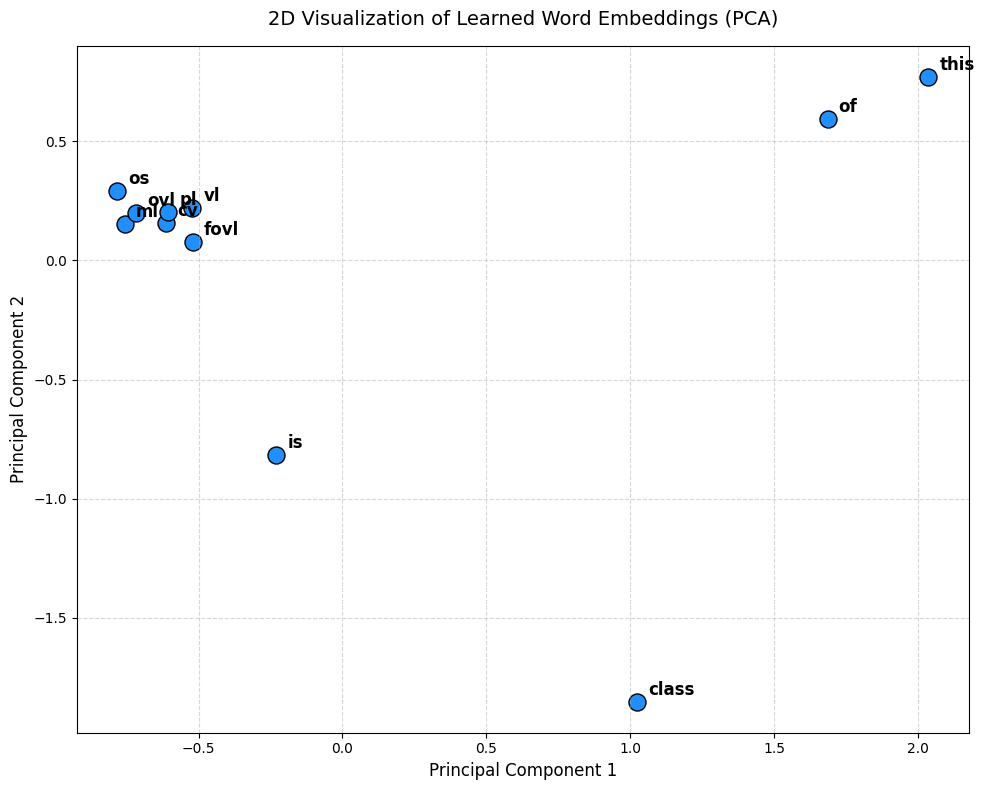

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Prepare the embedding matrix and labels
words = list(word2idx.keys())
embedding_matrix = np.array([E[word2idx[w]] for w in words])

# Perform PCA to reduce dimensionality to 2D
pca = PCA(n_components=2)
coords = pca.fit_transform(embedding_matrix)

# Create the plot
plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1], color='dodgerblue', edgecolors='k', s=150)

# Annotate the points with their corresponding words
for i, word in enumerate(words):
    plt.annotate(word, (coords[i, 0], coords[i, 1]), xytext=(8, 5), textcoords='offset points', fontsize=12, weight='bold')

plt.title("2D Visualization of Learned Word Embeddings (PCA)", fontsize=14, pad=15)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
word2idx

{'class': 0,
 'cv': 1,
 'fovl': 2,
 'is': 3,
 'ml': 4,
 'of': 5,
 'os': 6,
 'ovl': 7,
 'pl': 8,
 'this': 9,
 'vl': 10}

In [ ]:
# Vectorize the tokenized data
vectors = []
vocab_size = len(vocabulary)

# Fix: iterate over 'data' and tokenize each sentence on the fly
for sentence, label in data:
    words = sentence.lower().split()
    # Initialize a zero vector for the sentence
    vector = [0] * vocab_size
    for word in words:
        if word in vocabulary:
            vector[vocabulary[word]] = 1
    vectors.append([vector, label])

# Display the resulting vectors
for vector, label in vectors:
    print(f"Vector: {vector} -> Label: {label}")

Vector: [1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0] -> Label: 1


In [ ]:
training_pairs


[('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'fovl'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'fovl'),
 ('fovl', 'class'),
 ('fovl', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'ml'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'ml'),
 ('ml', 'class'),
 ('ml', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'cv'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'cv'),
 ('cv', 'class'),
 ('cv', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'os'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'os'),
 ('os', 'class'),
 ('os', 'of'),
 ('this', 'is'),
 ('this

In [ ]:
import numpy as np

# Let's demonstrate how Cross-Entropy Loss works in your Skip-Gram model
# Suppose our vocabulary size is 11, and the true context word is at index 2 ('fovl')
true_context_idx = 2

# 1. Create a true one-hot encoded vector (y_true)
y_true = np.zeros(11)
y_true[true_context_idx] = 1.0

# 2. Dummy predicted probabilities from the softmax layer (y_pred)
# (Assuming the model predicts 'fovl' with 60% probability)
y_pred = np.array([0.05, 0.05, 0.60, 0.05, 0.05, 0.05, 0.05, 0.05, 0.02, 0.03, 0.05])

# Add a small epsilon to prevent calculating log(0) which is undefined
epsilon = 1e-10

# Standard categorical cross entropy formula: - sum(y_true * log(y_pred))
cross_entropy_loss = -np.sum(y_true * np.log(y_pred + epsilon))

# Simplified formula for one-hot vectors (This is exactly what you used in your training loop!)
simplified_loss = -np.log(y_pred[true_context_idx] + epsilon)

print(f"True one-hot vector (y_true):\n{y_true}\n")
print(f"Predicted probabilities (y_pred):\n{y_pred}\n")
print(f"Standard Cross-Entropy Loss:\t\t {cross_entropy_loss:.4f}")
print(f"Simplified Loss (used in your code):\t {simplified_loss:.4f}")
print("\nAs you can see, they are mathematically identical!")

True one-hot vector (y_true):
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted probabilities (y_pred):
[0.05 0.05 0.6  0.05 0.05 0.05 0.05 0.05 0.02 0.03 0.05]

Standard Cross-Entropy Loss:		 0.5108
Simplified Loss (used in your code):	 0.5108

As you can see, they are mathematically identical!


### Negative Sampling Generator
Below is an implementation of negative sampling. For every positive pair $(w_{center}, w_{context})$, we sample $k$ negative words from our vocabulary that do not appear in the context of our center word.

In [3]:
import random

def generate_negative_samples(corpus, word2idx, c=2, k=3):
    """
    Generates positive and negative training samples for Word2Vec Skip-Gram.

    Parameters:
        corpus (list of str): The input sentences.
        word2idx (dict): Word-to-index vocabulary mapping.
        c (int): Context window size.
        k (int): Number of negative samples per positive pair.
    """
    tokenized_sentences = [sentence.lower().split() for sentence in corpus]
    vocab_indices = list(word2idx.values())
    dataset = []

    for sentence in tokenized_sentences:
        n = len(sentence)
        for i, w in enumerate(sentence):
            center_idx = word2idx[w]

            # Identify all actual context words in the window to avoid sampling them as negatives
            context_indices = set()
            for j in range(max(0, i - c), min(n, i + c + 1)):
                if i != j:
                    context_indices.add(word2idx[sentence[j]])

            for context_idx in context_indices:
                # 1. Positive pair (Label = 1)
                dataset.append((center_idx, context_idx, 1))

                # 2. Draw k Negative samples (Label = 0)
                neg_count = 0
                while neg_count < k:
                    neg_candidate = random.choice(vocab_indices)
                    # Ensure candidate is not the center word and not in the actual context window
                    if neg_candidate != center_idx and neg_candidate not in context_indices:
                        dataset.append((center_idx, neg_candidate, 0))
                        neg_count += 1

    return dataset

# Re-define corpus and vocabulary to ensure they are available in the current session
corpus = [
    "this is class of fovl",
    "this is class of ml",
    "this is class of cv",
    "this is class of os",
    "this is class of vl",
    "this is class of ovl",
    "this is class of pl"
]
vocab = sorted(list(set(word for sent in corpus for word in sent.lower().split())))
word2idx = {w: idx for idx, w in enumerate(vocab)}
idx2word = {idx: w for idx, w in enumerate(vocab)}

# Generate negative samples for our corpus
samples = generate_negative_samples(corpus, word2idx, c=2, k=3)

# Print a sample of the results
print(f"Generated total of {len(samples)} samples (Positives + Negatives)\n")
print(f"{'Center Word':<12} | {'Candidate Word':<15} | {'Label (1=Pos, 0=Neg)':<20}")
print("-" * 55)
for center, candidate, label in samples[:20]:
    print(f"{idx2word[center]:<12} | {idx2word[candidate]:<15} | {label:<20}")

Generated total of 392 samples (Positives + Negatives)

Center Word  | Candidate Word  | Label (1=Pos, 0=Neg)
-------------------------------------------------------
this         | class           | 1                   
this         | of              | 0                   
this         | cv              | 0                   
this         | fovl            | 0                   
this         | is              | 1                   
this         | vl              | 0                   
this         | of              | 0                   
this         | fovl            | 0                   
is           | class           | 1                   
is           | ml              | 0                   
is           | cv              | 0                   
is           | fovl            | 0                   
is           | this            | 1                   
is           | os              | 0                   
is           | os              | 0                   
is           | ml       

In [5]:
import numpy as np
import random

def sigmoid(x):
    # Sigmoid activation function for binary classification
    return 1 / (1 + np.exp(-np.clip(x, -15, 15)))

def train_negative_sampling(samples, vocab_size, embedding_dim=5, epochs=100, lr=0.05):
    # Initialize Target Embeddings (E) and Context Embeddings (W)
    np.random.seed(42)
    E = np.random.uniform(-0.5, 0.5, (vocab_size, embedding_dim))
    W = np.random.uniform(-0.5, 0.5, (vocab_size, embedding_dim))

    print("Starting Negative Sampling Training...")
    for epoch in range(1, epochs + 1):
        random.shuffle(samples)
        total_loss = 0.0

        for center, context, label in samples:
            h = E[center]   # Target word vector
            c = W[context]  # Context/Negative word vector

            # Dot product and prediction
            z = np.dot(h, c)
            pred = sigmoid(z)

            # Error
            error = pred - label

            # Compute Gradients
            grad_c = error * h
            grad_h = error * c

            # Update Weights
            W[context] -= lr * grad_c
            E[center] -= lr * grad_h

            # Accumulate loss for tracking
            # Binary Cross Entropy: -[y*log(y_hat) + (1-y)*log(1-y_hat)]
            loss = - (label * np.log(pred + 1e-10) + (1 - label) * np.log(1 - pred + 1e-10))
            total_loss += loss

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs} | Average Loss: {total_loss / len(samples):.4f}")

    return E

# Train the model
V = len(word2idx)
E_neg = train_negative_sampling(samples, V, embedding_dim=5, epochs=100, lr=0.05)
print("\nTraining complete!")

Starting Negative Sampling Training...
Epoch   1/100 | Average Loss: 0.6752
Epoch  20/100 | Average Loss: 0.1501
Epoch  40/100 | Average Loss: 0.1317
Epoch  60/100 | Average Loss: 0.1270
Epoch  80/100 | Average Loss: 0.1275
Epoch 100/100 | Average Loss: 0.1258

Training complete!


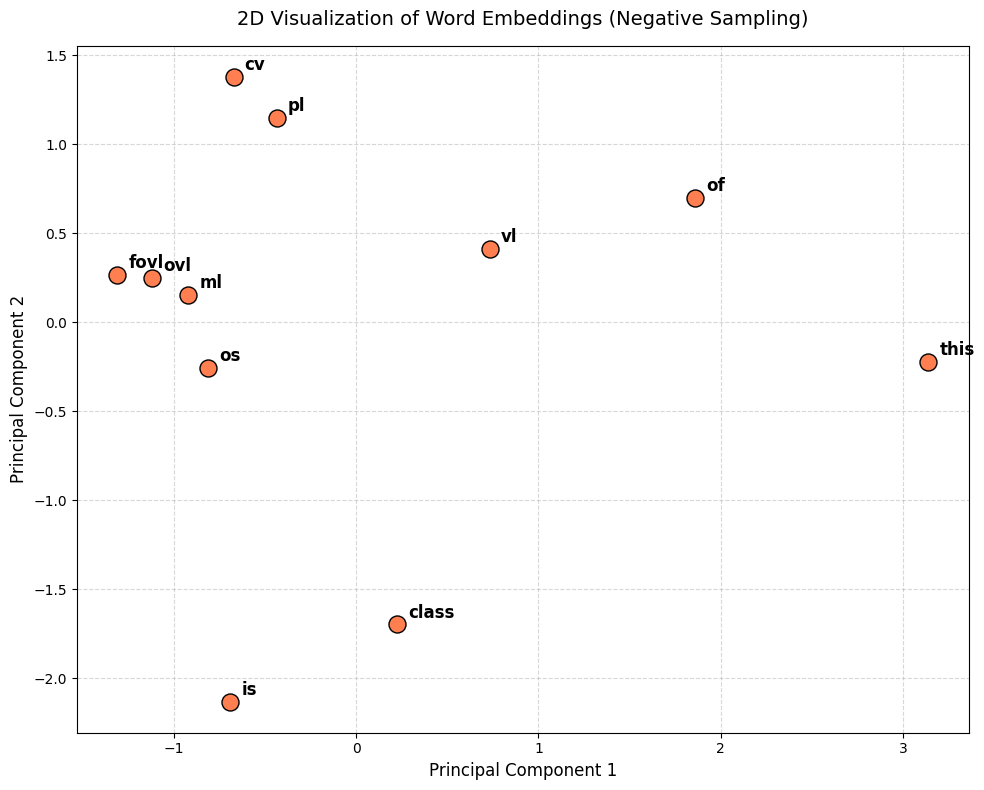

In [6]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Prepare the embedding matrix from the negative sampling model
words = list(word2idx.keys())
embedding_matrix_neg = np.array([E_neg[word2idx[w]] for w in words])

# Perform PCA to reduce dimensionality to 2D
pca_neg = PCA(n_components=2)
coords_neg = pca_neg.fit_transform(embedding_matrix_neg)

# Create the plot
plt.figure(figsize=(10, 8))
plt.scatter(coords_neg[:, 0], coords_neg[:, 1], color='coral', edgecolors='k', s=150)

# Annotate the points with their corresponding words
for i, word in enumerate(words):
    plt.annotate(word, (coords_neg[i, 0], coords_neg[i, 1]),
                 xytext=(8, 5), textcoords='offset points',
                 fontsize=12, weight='bold')

plt.title("2D Visualization of Word Embeddings (Negative Sampling)", fontsize=14, pad=15)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### GloVe (Global Vectors for Word Representation)
First, we build the global co-occurrence matrix $X$ where $X_{ij}$ represents how often word $j$ appears in the context of word $i$. In GloVe, it's standard practice to weight the co-occurrence count by the inverse of the distance between the words.

In [4]:
import numpy as np

# Re-define corpus and vocabulary to ensure they are available in the current session
corpus = [
    "this is class of fovl",
    "this is class of ml",
    "this is class of cv",
    "this is class of os",
    "this is class of vl",
    "this is class of ovl",
    "this is class of pl"
]
vocab = sorted(list(set(word for sent in corpus for word in sent.lower().split())))
word2idx = {w: idx for idx, w in enumerate(vocab)}

# 1. Build the Co-occurrence Matrix
vocab_size = len(word2idx)
window_size = 2
X = np.zeros((vocab_size, vocab_size))

for sentence in corpus:
    words_in_sent = sentence.lower().split()
    n = len(words_in_sent)
    for i, w_i in enumerate(words_in_sent):
        idx_i = word2idx[w_i]
        for j in range(max(0, i - window_size), min(n, i + window_size + 1)):
            if i != j:
                idx_j = word2idx[words_in_sent[j]]
                distance = abs(i - j)
                # GloVe typically weights co-occurrences by 1/distance
                X[idx_i, idx_j] += 1.0 / distance

print("Co-occurrence Matrix (X) shape:", X.shape)
print("Sample of X (first 5x5):\n", X[:5, :5])

Co-occurrence Matrix (X) shape: (11, 11)
Sample of X (first 5x5):
 [[0.  0.5 0.5 7.  0.5]
 [0.5 0.  0.  0.  0. ]
 [0.5 0.  0.  0.  0. ]
 [7.  0.  0.  0.  0. ]
 [0.5 0.  0.  0.  0. ]]


Now we implement the GloVe training loop. The loss function is:
$$ J = \sum_{i, j=1}^{V} f(X_{ij}) (w_i^T \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij})^2 $$
Where $f(X_{ij})$ is a weighting function that caps at $x_{max}$.

Starting GloVe Training...
Epoch    1/1000 | Loss: 19.3343
Epoch  200/1000 | Loss: 0.1661
Epoch  400/1000 | Loss: 0.0318
Epoch  600/1000 | Loss: 0.0095
Epoch  800/1000 | Loss: 0.0029
Epoch 1000/1000 | Loss: 0.0009

GloVe Training complete!


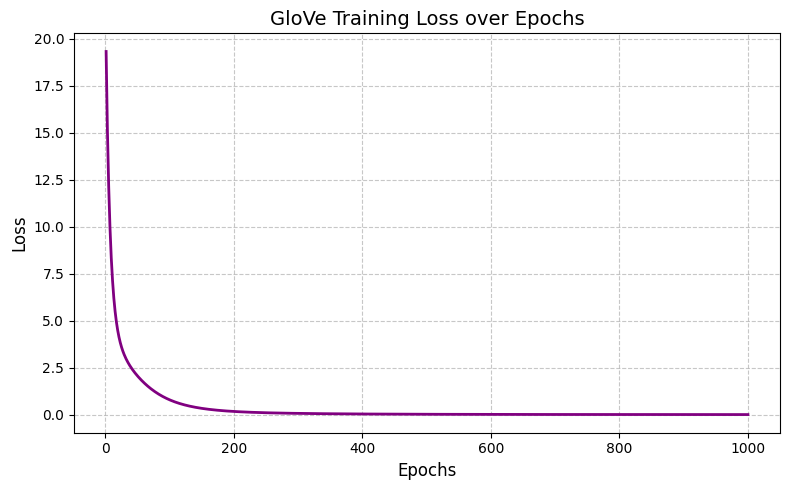

In [10]:
import matplotlib.pyplot as plt
import numpy as np

def train_glove(X, vocab_size, embedding_dim=5, epochs=500, lr=0.05, x_max=10, alpha=0.75):
    # Initialize Target/Context vectors and biases
    np.random.seed(42)
    W = np.random.uniform(-0.5, 0.5, (vocab_size, embedding_dim))
    W_tilde = np.random.uniform(-0.5, 0.5, (vocab_size, embedding_dim))
    b = np.random.uniform(-0.5, 0.5, (vocab_size,))
    b_tilde = np.random.uniform(-0.5, 0.5, (vocab_size,))

    # Weighting function
    def f_weight(x):
        if x < x_max:
            return (x / x_max) ** alpha
        return 1.0

    loss_history = []
    print("Starting GloVe Training...")
    for epoch in range(1, epochs + 1):
        total_loss = 0.0

        for i in range(vocab_size):
            for j in range(vocab_size):
                if X[i, j] == 0:
                    continue  # Log(0) is undefined, so we skip zero co-occurrences

                weight = f_weight(X[i, j])
                log_x = np.log(X[i, j])

                # Inner component: w_i^T * w_tilde_j + b_i + b_tilde_j - log(X_ij)
                inner = np.dot(W[i], W_tilde[j]) + b[i] + b_tilde[j] - log_x

                # Loss accumulation
                loss = weight * (inner ** 2)
                total_loss += loss

                # Compute Gradients
                grad_inner = 2 * weight * inner
                grad_W_i = grad_inner * W_tilde[j]
                grad_W_tilde_j = grad_inner * W[i]
                grad_b_i = grad_inner
                grad_b_tilde_j = grad_inner

                # Update Weights & Biases
                W[i] -= lr * grad_W_i
                W_tilde[j] -= lr * grad_W_tilde_j
                b[i] -= lr * grad_b_i
                b_tilde[j] -= lr * grad_b_tilde_j

        loss_history.append(total_loss)
        if epoch % (epochs // 5) == 0 or epoch == 1:
            print(f"Epoch {epoch:4d}/{epochs} | Loss: {total_loss:.4f}")

    # In GloVe, the final embedding is typically the sum of the target and context representations
    return W + W_tilde, loss_history

# Train the GloVe model
E_glove, glove_loss_history = train_glove(X, vocab_size, embedding_dim=5, epochs=1000, lr=0.01)
print("\nGloVe Training complete!")

# Plot the training loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(glove_loss_history) + 1), glove_loss_history, color='purple', linewidth=2)
plt.title('GloVe Training Loss over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

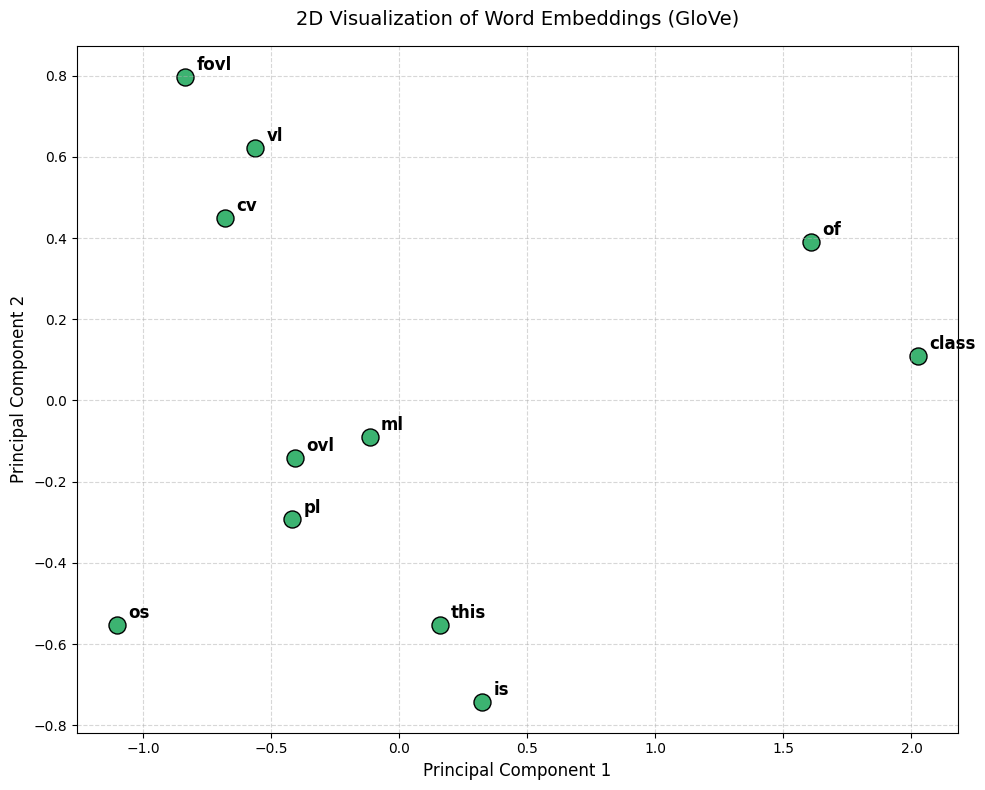

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Prepare the embedding matrix from the GloVe model
words = list(word2idx.keys())
embedding_matrix_glove = np.array([E_glove[word2idx[w]] for w in words])

# Perform PCA to reduce dimensionality to 2D
pca_glove = PCA(n_components=2)
coords_glove = pca_glove.fit_transform(embedding_matrix_glove)

# Create the plot
plt.figure(figsize=(10, 8))
plt.scatter(coords_glove[:, 0], coords_glove[:, 1], color='mediumseagreen', edgecolors='k', s=150)

# Annotate the points with their corresponding words
for i, word in enumerate(words):
    plt.annotate(word, (coords_glove[i, 0], coords_glove[i, 1]),
                 xytext=(8, 5), textcoords='offset points',
                 fontsize=12, weight='bold')

plt.title("2D Visualization of Word Embeddings (GloVe)", fontsize=14, pad=15)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()